In [ ]:
# CELL 1 - IMPORT LIBRARIES

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

print("=" * 70)
print("NOTEBOOK 07 - GRAD-CAM EXPLAINABILITY")
print("=" * 70)

print()
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

NOTEBOOK 07 - GRAD-CAM EXPLAINABILITY

TensorFlow version: 2.21.0
NumPy version: 2.4.6


In [ ]:
#  CONFIGURATION

IMG_SIZE = (224, 224)

BATCH_SIZE = 32

SEED = 42

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

print("Image size:", IMG_SIZE)
print("Classes:", CLASS_NAMES)

Image size: (224, 224)
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
#  FIND PROJECT ROOT


current_path = Path.cwd().resolve()

PROJECT_ROOT = None

for path in [current_path] + list(current_path.parents):

    if (path / "data" / "raw").exists():

        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:

    raise FileNotFoundError(
        "Could not find project root containing data/raw"
    )

print("Project root:")
print(PROJECT_ROOT)

Project root:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection


In [ ]:
# DEFINE PROJECT PATHS

RAW_DIR = (
    PROJECT_ROOT /
    "data" /
    "raw"
)

RESULTS_DIR = (
    PROJECT_ROOT /
    "results"
)

GRADCAM_DIR = (
    RESULTS_DIR /
    "gradcam"
)

FIGURES_DIR = (
    RESULTS_DIR /
    "figures"
)

MODEL_PATH = (
    PROJECT_ROOT /
    "models" /
    "resnet50" /
    "best_resnet50.keras"
)

# Create output directories

GRADCAM_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Model path:")
print(MODEL_PATH)

print()

print("Grad-CAM output folder:")
print(GRADCAM_DIR)

if not MODEL_PATH.exists():

    raise FileNotFoundError(
        f"ResNet50 model not found:\n{MODEL_PATH}"
    )

print()
print("Model file found successfully.")

Model path:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\models\resnet50\best_resnet50.keras

Grad-CAM output folder:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam

Model file found successfully.


In [ ]:
# FIND TESTING DIRECTORY

testing_dirs = list(
    RAW_DIR.rglob("Testing")
)

if len(testing_dirs) == 0:

    raise FileNotFoundError(
        "Testing folder was not found."
    )

TEST_DIR = testing_dirs[0]

print("Testing directory:")
print(TEST_DIR)

Testing directory:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\data\raw\Testing


In [ ]:
# DETECT CLASSES


detected_classes = sorted(

    [
        folder.name

        for folder in TEST_DIR.iterdir()

        if folder.is_dir()
    ]
)

print("Detected classes:")

for i, class_name in enumerate(
    detected_classes
):

    print(
        f"{i}: {class_name}"
    )

if detected_classes != CLASS_NAMES:

    print()
    print("WARNING:")
    print("Expected:", CLASS_NAMES)
    print("Detected:", detected_classes)

    # Use actual detected classes if needed
    CLASS_NAMES = detected_classes

print()
print("Final class order:")
print(CLASS_NAMES)

Detected classes:
0: glioma
1: meningioma
2: notumor
3: pituitary

Final class order:
['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
#RESNET50 PREPROCESSING LAYER


@tf.keras.utils.register_keras_serializable()
class ResNet50Preprocess(
    tf.keras.layers.Layer
):

    def call(self, inputs):

        return tf.keras.applications.resnet50.preprocess_input(
            inputs
        )

print("ResNet50 preprocessing layer registered.")

ResNet50 preprocessing layer registered.


In [ ]:
# LOAD RESNET50 MODEL


print("Loading ResNet50...")

resnet_model = tf.keras.models.load_model(

    MODEL_PATH,

    custom_objects={
        "ResNet50Preprocess":
            ResNet50Preprocess
    }

)

print()
print("ResNet50 loaded successfully.")

print()
print("Model name:")
print(resnet_model.name)

print()
print("Input shape:")
print(resnet_model.input_shape)

print()
print("Output shape:")
print(resnet_model.output_shape)

Loading ResNet50...

ResNet50 loaded successfully.

Model name:
ResNet50

Input shape:
(None, 224, 224, 3)

Output shape:
(None, 4)


In [ ]:
#  INSPECT MODEL LAYERS

print("=" * 70)
print("MODEL LAYERS")
print("=" * 70)

for i, layer in enumerate(
    resnet_model.layers
):

    print(
        i,
        "|",
        layer.name,
        "|",
        type(layer).__name__
    )

MODEL LAYERS
0 | input_layer_1 | InputLayer
1 | transfer_augmentation | Sequential
2 | res_net50_preprocess | ResNet50Preprocess
3 | resnet50 | Functional
4 | global_average_pooling2d | GlobalAveragePooling2D
5 | batch_normalization | BatchNormalization
6 | dense | Dense
7 | dropout | Dropout
8 | dense_1 | Dense


In [ ]:
# FIND NESTED RESNET50 BACKBONE


backbone = None

for layer in resnet_model.layers:

    if isinstance(
        layer,
        tf.keras.Model
    ):

        if "resnet" in layer.name.lower():

            backbone = layer
            break

if backbone is None:

    raise ValueError(
        "Could not find the nested ResNet50 backbone."
    )

print("ResNet50 backbone found:")
print(backbone.name)

print()
print("Backbone input:")
print(backbone.input.shape)

print()
print("Backbone output:")
print(backbone.output.shape)

ResNet50 backbone found:
resnet50

Backbone input:
(None, 224, 224, 3)

Backbone output:
(None, 7, 7, 2048)


In [ ]:
# CELL 11 - FIND LAST CONVOLUTIONAL LAYER

last_conv_layer = None

print("=" * 70)
print("SEARCHING FOR LAST CONVOLUTIONAL LAYER")
print("=" * 70)

for layer in backbone.layers:

    try:

        output_shape = layer.output.shape

        # We want a 4D feature map:
        # (batch, height, width, channels)

        if len(output_shape) == 4:

            if (
                output_shape[1] is not None
                and output_shape[2] is not None
                and output_shape[3] is not None
            ):

                last_conv_layer = layer

    except Exception:

        continue


if last_conv_layer is None:

    raise ValueError(
        "Could not find a suitable 4D convolutional feature layer."
    )

print()
print("Selected Grad-CAM layer:")
print(last_conv_layer.name)

print()
print("Layer type:")
print(type(last_conv_layer).__name__)

print()
print("Layer output shape:")
print(last_conv_layer.output.shape)

SEARCHING FOR LAST CONVOLUTIONAL LAYER

Selected Grad-CAM layer:
conv5_block3_out

Layer type:
Activation

Layer output shape:
(None, 7, 7, 2048)


In [ ]:
# CELL 12 - FIND TEST IMAGES

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

test_images = []

for class_name in CLASS_NAMES:

    class_dir = (
        TEST_DIR /
        class_name
    )

    if not class_dir.exists():

        continue

    for image_path in class_dir.rglob("*"):

        if (
            image_path.is_file()
            and
            image_path.suffix.lower()
            in IMAGE_EXTENSIONS
        ):

            test_images.append({

                "path": image_path,

                "true_class": class_name

            })

print(
    "Total test images found:",
    len(test_images)
)

if len(test_images) == 0:

    raise ValueError(
        "No test images found."
    )

Total test images found: 1600


In [ ]:
# CELL 14 - CREATE CORRECTED GRAD-CAM MODEL


print("=" * 70)
print("CREATING CORRECTED GRAD-CAM MODEL")
print("=" * 70)

# ------------------------------------------------------------
# IMPORTANT:
# Do NOT create a model connecting:
#
# resnet_model.input -> backbone.input
#
# because the loaded Keras model is nested.
#
# Instead, work directly inside the ResNet50 backbone.
# ------------------------------------------------------------


# Find the ResNet50 backbone again
backbone = None

for layer in resnet_model.layers:

    if isinstance(layer, tf.keras.Model):

        if "resnet" in layer.name.lower():

            backbone = layer
            break


if backbone is None:

    raise ValueError(
        "Could not find ResNet50 backbone."
    )


print()
print("Backbone:")
print(backbone.name)


# ------------------------------------------------------------
# Find last convolutional feature layer
# ------------------------------------------------------------

last_conv_layer = None

for layer in backbone.layers:

    try:

        shape = layer.output.shape

        if len(shape) == 4:

            if (
                shape[1] is not None
                and shape[2] is not None
                and shape[3] is not None
            ):

                last_conv_layer = layer

    except Exception:

        continue


if last_conv_layer is None:

    raise ValueError(
        "Could not find a suitable convolutional layer."
    )


print()
print("Grad-CAM layer:")
print(last_conv_layer.name)

print()
print("Grad-CAM layer output:")
print(last_conv_layer.output.shape)


# ------------------------------------------------------------
# Create model INSIDE the ResNet50 backbone only
# ------------------------------------------------------------

grad_model = tf.keras.models.Model(

    inputs=backbone.input,

    outputs=[
        last_conv_layer.output,
        backbone.output
    ],

    name="resnet50_gradcam_model"

)


print()
print("Grad-CAM model created successfully.")

print()
print("Grad-CAM model input:")
print(grad_model.input.shape)

print()
print("Grad-CAM model outputs:")

for output in grad_model.outputs:

    print(output.shape)

CREATING CORRECTED GRAD-CAM MODEL

Backbone:
resnet50

Grad-CAM layer:
conv5_block3_out

Grad-CAM layer output:
(None, 7, 7, 2048)

Grad-CAM model created successfully.

Grad-CAM model input:
(None, 224, 224, 3)

Grad-CAM model outputs:
(None, 7, 7, 2048)
(None, 7, 7, 2048)


In [ ]:
# CORRECTED GRAD-CAM FUNCTION

def make_gradcam_heatmap(
    image,
    pred_index=None
):

    # --------------------------------------------------------
    # Convert image to float32
    # --------------------------------------------------------

    image = tf.cast(
        image,
        tf.float32
    )


    # --------------------------------------------------------
    # Apply the SAME preprocessing used by ResNet50
    #
    # This is equivalent to the preprocessing layer used
    # when the model was trained.
    # --------------------------------------------------------

    preprocessed_image = (
        tf.keras.applications.resnet50.preprocess_input(
            image
        )
    )


    # --------------------------------------------------------
    # Gradient calculation
    # --------------------------------------------------------

    with tf.GradientTape() as tape:

        # Get:
        # 1. convolutional feature maps
        # 2. backbone output

        conv_outputs, backbone_output = (
            grad_model(
                preprocessed_image
            )
        )


        # ----------------------------------------------------
        # Pass backbone output through the classification head
        # ----------------------------------------------------

        predictions = backbone_output


        # Find backbone position in outer model

        backbone_index = None

        for i, layer in enumerate(
            resnet_model.layers
        ):

            if layer is backbone:

                backbone_index = i

                break


        if backbone_index is None:

            raise ValueError(
                "Could not find backbone in outer model."
            )


        # Apply layers after ResNet50 backbone

        for layer in resnet_model.layers[
            backbone_index + 1:
        ]:

            predictions = layer(
                predictions
            )


        # ----------------------------------------------------
        # Select target class
        # ----------------------------------------------------

        if pred_index is None:

            pred_index = tf.argmax(
                predictions[0]
            )


        class_channel = (
            predictions[:, pred_index]
        )


    # --------------------------------------------------------
    # Calculate gradients
    # --------------------------------------------------------

    grads = tape.gradient(

        class_channel,

        conv_outputs

    )


    if grads is None:

        raise ValueError(
            "Gradients are None. "
            "Grad-CAM could not calculate gradients."
        )


    # --------------------------------------------------------
    # Global average pooling of gradients
    # --------------------------------------------------------

    pooled_grads = tf.reduce_mean(

        grads,

        axis=(0, 1, 2)

    )


    # --------------------------------------------------------
    # Remove batch dimension
    # --------------------------------------------------------

    conv_outputs = (
        conv_outputs[0]
    )


    # --------------------------------------------------------
    # Weight feature maps
    # --------------------------------------------------------

    heatmap = tf.reduce_sum(

        conv_outputs *
        pooled_grads,

        axis=-1

    )


    # --------------------------------------------------------
    # ReLU
    # --------------------------------------------------------

    heatmap = tf.maximum(

        heatmap,

        0

    )


    # --------------------------------------------------------
    # Normalize heatmap
    # --------------------------------------------------------

    max_value = tf.reduce_max(
        heatmap
    )


    heatmap = tf.where(

        max_value > 0,

        heatmap / max_value,

        tf.zeros_like(
            heatmap
        )

    )


    return (

        heatmap.numpy(),

        predictions.numpy()

    )


print(
    "Corrected Grad-CAM function created successfully."
)

Corrected Grad-CAM function created successfully.


In [ ]:
#TEST GRAD-CAM ON ONE IMAGE

print("=" * 70)
print("TESTING GRAD-CAM")
print("=" * 70)


# Select first test image
test_item = test_images[0]


print()
print("Image:")
print(test_item["path"])


# Load image
original_image, model_input = (
    load_image(
        test_item["path"]
    )
)


# ------------------------------------------------------------
# Normal ResNet50 prediction
# ------------------------------------------------------------

predictions = (
    resnet_model.predict(

        model_input,

        verbose=0

    )
)


predicted_index = int(

    np.argmax(
        predictions[0]
    )

)


predicted_class = (
    CLASS_NAMES[
        predicted_index
    ]
)


confidence = float(

    predictions[0][
        predicted_index
    ]

)


print()
print("True class:")
print(
    test_item["true_class"]
)


print()
print("Predicted class:")
print(
    predicted_class
)


print()
print("Confidence:")
print(
    f"{confidence * 100:.2f}%"
)


# ------------------------------------------------------------
# Generate Grad-CAM
# ------------------------------------------------------------

heatmap, prediction_output = (

    make_gradcam_heatmap(

        model_input,

        pred_index=predicted_index

    )

)


print()
print("SUCCESS!")

print()
print("Heatmap shape:")
print(
    heatmap.shape
)

TESTING GRAD-CAM

Image:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\data\raw\Testing\glioma\Te-gl_1.jpg

True class:
glioma

Predicted class:
glioma

Confidence:
39.91%

SUCCESS!

Heatmap shape:
(7, 7)


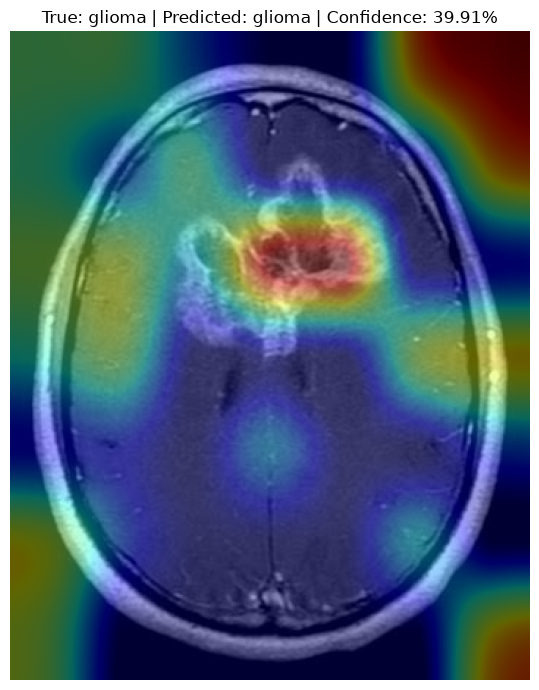

In [ ]:
# DISPLAY GRAD-CAM


test_overlay = (
    create_gradcam_overlay(

        original_image,

        heatmap,

        alpha=0.40

    )
)


plt.figure(
    figsize=(8, 7)
)


plt.imshow(
    test_overlay
)


plt.axis(
    "off"
)


plt.title(

    f"True: {test_item['true_class']} | "
    f"Predicted: {predicted_class} | "
    f"Confidence: {confidence * 100:.2f}%"

)


plt.tight_layout()

plt.show()

In [ ]:
# SELECT ONE CORRECTLY CLASSIFIED IMAGE PER CLASS


selected_images = []

print("=" * 70)
print("SEARCHING FOR CORRECTLY CLASSIFIED IMAGES")
print("=" * 70)

for class_index, class_name in enumerate(
    CLASS_NAMES
):

    class_images = [

        item

        for item in test_images

        if item["true_class"] == class_name

    ]

    found = False

    for item in class_images:

        original_image_temp, model_input_temp = (
            load_image(
                item["path"]
            )
        )

        predictions_temp = (
            resnet_model.predict(
                model_input_temp,
                verbose=0
            )
        )

        predicted_index_temp = int(
            np.argmax(
                predictions_temp[0]
            )
        )

        if predicted_index_temp == class_index:

            confidence_temp = float(
                predictions_temp[0][
                    predicted_index_temp
                ]
            )

            selected_images.append({

                "path":
                    item["path"],

                "true_class":
                    class_name,

                "predicted_class":
                    CLASS_NAMES[
                        predicted_index_temp
                    ],

                "confidence":
                    confidence_temp

            })

            print()
            print(f"✓ {class_name}")

            print(
                "  File:",
                item["path"].name
            )

            print(
                "  Confidence:",
                f"{confidence_temp * 100:.2f}%"
            )

            found = True

            break

    if not found:

        print()
        print(
            f"✗ No correctly classified "
            f"{class_name} image found."
        )

print()
print(
    "Total selected images:",
    len(selected_images)
)

SEARCHING FOR CORRECTLY CLASSIFIED IMAGES

✓ glioma
  File: Te-gl_1.jpg
  Confidence: 39.91%

✓ meningioma
  File: Te-aug-me_1.jpg
  Confidence: 94.21%

✓ notumor
  File: Te-no_1.jpg
  Confidence: 95.29%

✓ pituitary
  File: Te-pi_1.jpg
  Confidence: 98.63%

Total selected images: 4


In [ ]:
# GENERATE GRAD-CAM FOR SELECTED IMAGES


gradcam_results = []

print("=" * 70)
print("GENERATING GRAD-CAM RESULTS")
print("=" * 70)

for item in selected_images:

    image_path = item["path"]

    # Load image
    original_image, model_input = (
        load_image(
            image_path
        )
    )

    # Prediction
    predictions = (
        resnet_model.predict(
            model_input,
            verbose=0
        )
    )

    predicted_index = int(
        np.argmax(
            predictions[0]
        )
    )

    predicted_class = (
        CLASS_NAMES[
            predicted_index
        ]
    )

    confidence = float(
        predictions[0][
            predicted_index
        ]
    )

    # Generate Grad-CAM
    heatmap, _ = (
        make_gradcam_heatmap(
            model_input,
            pred_index=predicted_index
        )
    )

    # Create overlay
    overlay = create_gradcam_overlay(
        original_image,
        heatmap,
        alpha=0.40
    )

    # Save file
    output_path = (
        GRADCAM_DIR /
        f"gradcam_{item['true_class']}.png"
    )

    overlay.save(
        output_path
    )

    # Store result
    gradcam_results.append({

        "true_class":
            item["true_class"],

        "predicted_class":
            predicted_class,

        "confidence":
            confidence,

        "original_image":
            str(image_path),

        "gradcam_image":
            str(output_path)

    })

    print()
    print(
        "True class:",
        item["true_class"]
    )

    print(
        "Predicted class:",
        predicted_class
    )

    print(
        "Confidence:",
        f"{confidence * 100:.2f}%"
    )

    print(
        "Saved:",
        output_path
    )


print()
print("Grad-CAM generation completed.")

GENERATING GRAD-CAM RESULTS

True class: glioma
Predicted class: glioma
Confidence: 39.91%
Saved: C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam\gradcam_glioma.png

True class: meningioma
Predicted class: meningioma
Confidence: 94.21%
Saved: C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam\gradcam_meningioma.png

True class: notumor
Predicted class: notumor
Confidence: 95.29%
Saved: C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam\gradcam_notumor.png

True class: pituitary
Predicted class: pituitary
Confidence: 98.63%
Saved: C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam\gradcam_pituitary.png

Grad-CAM generation completed.


In [ ]:
# CELL 21 - GRAD-CAM RESULTS TABLE

gradcam_df = pd.DataFrame(
    gradcam_results
)

print("=" * 70)
print("GRAD-CAM RESULTS")
print("=" * 70)

display(
    gradcam_df
)

GRAD-CAM RESULTS


,true_class,predicted_class,confidence,original_image,gradcam_image
0,glioma,glioma,0.399105,C:\Users\khala\Project\Tumor_Detection\Tumor_D...,C:\Users\khala\Project\Tumor_Detection\Tumor_D...
1,meningioma,meningioma,0.942088,C:\Users\khala\Project\Tumor_Detection\Tumor_D...,C:\Users\khala\Project\Tumor_Detection\Tumor_D...
2,notumor,notumor,0.952942,C:\Users\khala\Project\Tumor_Detection\Tumor_D...,C:\Users\khala\Project\Tumor_Detection\Tumor_D...
3,pituitary,pituitary,0.986285,C:\Users\khala\Project\Tumor_Detection\Tumor_D...,C:\Users\khala\Project\Tumor_Detection\Tumor_D...


In [ ]:
# CELL 22 - SAVE GRAD-CAM RESULTS CSV

gradcam_csv_path = (
    RESULTS_DIR /
    "gradcam_results.csv"
)

gradcam_df.to_csv(
    gradcam_csv_path,
    index=False
)

print()
print("Grad-CAM results saved to:")

print(
    gradcam_csv_path
)


Grad-CAM results saved to:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam_results.csv


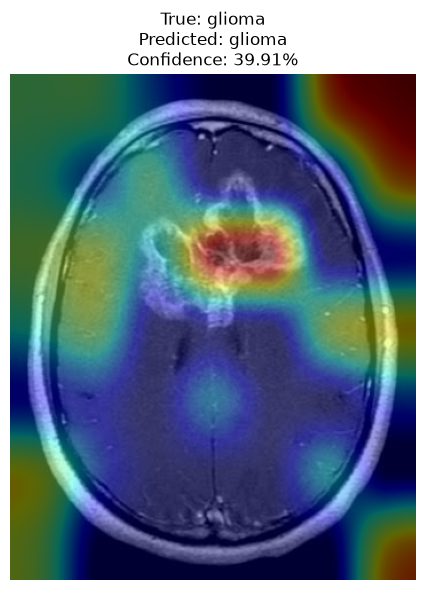

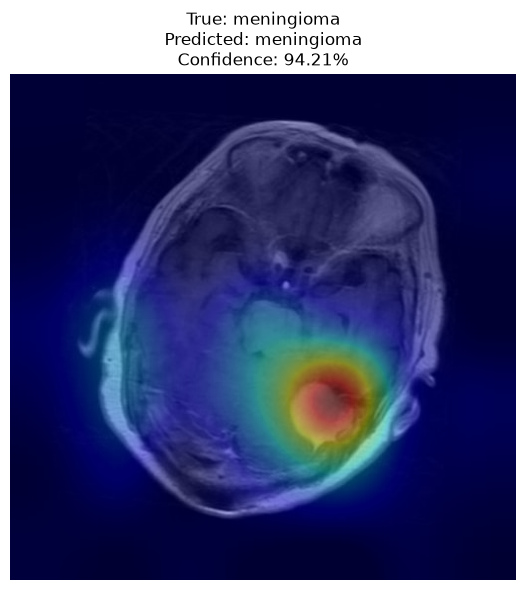

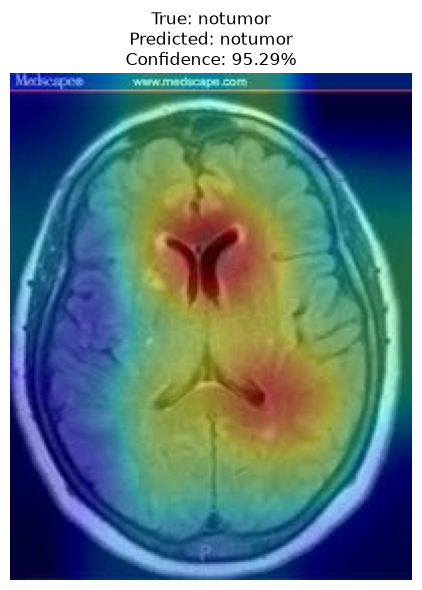

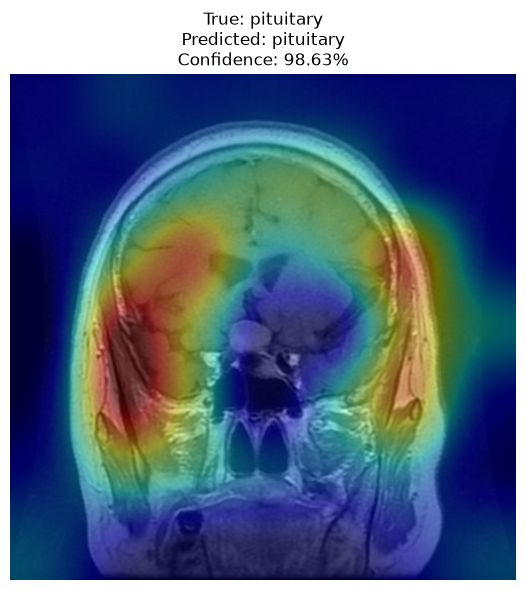

In [ ]:
# DISPLAY INDIVIDUAL GRAD-CAM IMAGES


for item in gradcam_results:

    image = Image.open(
        item["gradcam_image"]
    )

    plt.figure(
        figsize=(7, 6)
    )

    plt.imshow(
        image
    )

    plt.axis("off")

    plt.title(

        f"True: {item['true_class']}\n"
        f"Predicted: {item['predicted_class']}\n"
        f"Confidence: "
        f"{item['confidence'] * 100:.2f}%"

    )

    plt.tight_layout()

    plt.show()

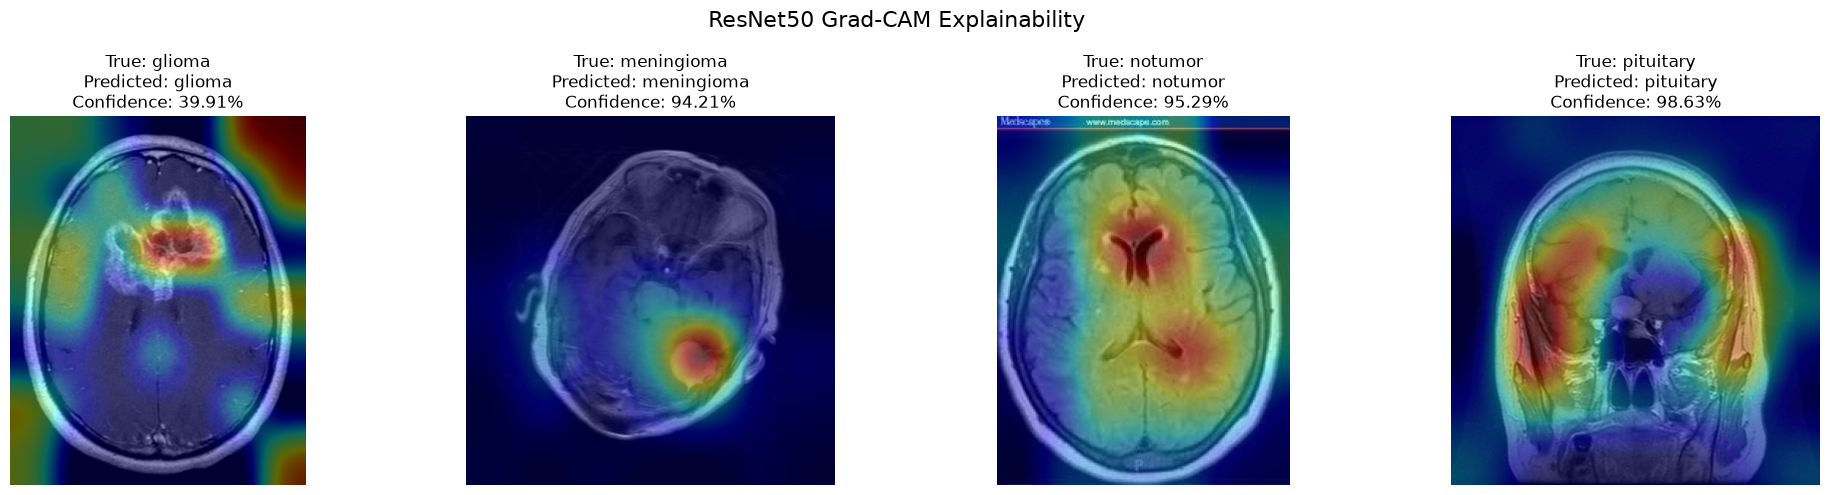


Combined Grad-CAM figure saved:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam\resnet50_gradcam_combined.png


In [ ]:
#CREATE COMBINED GRAD-CAM FIGURE


num_images = len(
    gradcam_results
)

if num_images == 0:

    raise ValueError(
        "No Grad-CAM results available."
    )

fig, axes = plt.subplots(

    1,

    num_images,

    figsize=(
        5 * num_images,
        5
    )

)

if num_images == 1:

    axes = [axes]

for ax, item in zip(
    axes,
    gradcam_results
):

    image = Image.open(
        item["gradcam_image"]
    )

    ax.imshow(
        image
    )

    ax.axis("off")

    ax.set_title(

        f"True: "
        f"{item['true_class']}\n"

        f"Predicted: "
        f"{item['predicted_class']}\n"

        f"Confidence: "
        f"{item['confidence'] * 100:.2f}%"

    )

plt.suptitle(
    "ResNet50 Grad-CAM Explainability",
    fontsize=16
)

plt.tight_layout()

combined_path = (
    GRADCAM_DIR /
    "resnet50_gradcam_combined.png"
)

plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print()
print("Combined Grad-CAM figure saved:")
print(combined_path)

In [ ]:
# VERIFY GRAD-CAM OUTPUT FILES

print("=" * 70)
print("GRAD-CAM OUTPUT FILES")
print("=" * 70)

for file in sorted(
    GRADCAM_DIR.iterdir()
):

    print(
        file.name
    )

GRAD-CAM OUTPUT FILES
gradcam_glioma.png
gradcam_meningioma.png
gradcam_notumor.png
gradcam_pituitary.png
resnet50_gradcam_combined.png


In [ ]:
# FINAL SUMMARY


print()
print()
print("=" * 70)
print("NOTEBOOK 07 COMPLETED SUCCESSFULLY")
print("=" * 70)

print()

print("Final selected model:")
print("ResNet50")

print()

print("Test Accuracy:")
print("93.31%")

print()

print("Precision:")
print("93.61%")

print()

print("Recall:")
print("93.31%")

print()

print("F1 Score:")
print("93.16%")

print()

print("Grad-CAM folder:")
print(GRADCAM_DIR)

print()

print("Grad-CAM CSV:")
print(gradcam_csv_path)

print()

print("Combined Grad-CAM:")
print(combined_path)

print()

print("=" * 70)
print("ALL PROJECT NOTEBOOKS COMPLETED")
print("=" * 70)



NOTEBOOK 07 COMPLETED SUCCESSFULLY

Final selected model:
ResNet50

Test Accuracy:
93.31%

Precision:
93.61%

Recall:
93.31%

F1 Score:
93.16%

Grad-CAM folder:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam

Grad-CAM CSV:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam_results.csv

Combined Grad-CAM:
C:\Users\khala\Project\Tumor_Detection\Tumor_Detection\results\gradcam\resnet50_gradcam_combined.png

ALL PROJECT NOTEBOOKS COMPLETED
